# Zenn トピック分析

[fa0311/zenn-icons](https://github.com/fa0311/zenn-icons) に毎月コミットされる `metadata.json`（Zenn 全トピックのスナップショット）を使って、トピックのトレンドを分析する。

- **データ更新**: `uv run python fetch_data.py` で `data/` に全スナップショットをダウンロード
- **スキーマ**: トピック名 → `{articlesCount, taggingsCount, booksCount, scrapsCount, displayName, ...}`
- **注意**: コミット間隔は不均一（2025-03→2025-06 に欠落あり）なので、ランキングは「1日あたり増加数」も併記する

## 目次

1. **セットアップとデータロード**
2. **ランキング** — 急上昇 / 相対成長率 / モメンタム（加速・失速） / 新規登場
3. **トピック比較** — AI / フロントエンド / Nix・環境構築 / ネイティブアプリ / テーマ別
4. **マクロ視点** — シェア推移 / AI vs 非AI / 成長ヒートマップ
5. **記事以外の指標** — スクラップ・本
6. **付録** — トピック検索

## 主な道具

| 関数 | 用途 |
|---|---|
| `rising_ranking(months_back)` | 記事数の増加ランキング（`ascending=True` で下降） |
| `growth_ranking(months_back, min_start)` | 相対成長率ランキング（規模フィルタ付き） |
| `momentum_ranking()` | 直近で加速・失速しているトピック |
| `newcomer_ranking(months_back)` | 期間中に初登場したトピック |
| `plot_topics([...])` | 折れ線比較（`rate=` / `normalize=` / `metric=` / `ax=`） |
| `compare_topics([...])` | **絶対数と相対成長をセットで表示**（比較の基本形） |
| `plot_growth_heatmap()` | トピック × 期間の増加ペースのヒートマップ |
| `search_topics("キーワード")` | トピック名の検索 |


## 1. セットアップとデータロード


In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401  日本語トピック名をグラフに描画するため
import pandas as pd

# カテゴリカル8色（ライトモード・固定順）とチャートの chrome
SERIES = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.prop_cycle": plt.cycler(color=SERIES),
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 1,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 1,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": INK,
    "axes.titlecolor": INK,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
})
pd.options.display.max_rows = 100


In [2]:
frames = []
for path in sorted(Path("data").glob("*.json")):
    snap = pd.DataFrame.from_dict(json.loads(path.read_text()), orient="index")
    snap["date"] = pd.Timestamp(path.stem)
    frames.append(snap)

long_df = pd.concat(frames, ignore_index=True)
display_names = long_df.drop_duplicates("name", keep="last").set_index("name")["displayName"]

# 日付 × トピック のマトリクス（そのスナップショットに存在しないトピックは NaN）
articles = long_df.pivot(index="date", columns="name", values="articlesCount")
taggings = long_df.pivot(index="date", columns="name", values="taggingsCount")
scraps = long_df.pivot(index="date", columns="name", values="scrapsCount")
books = long_df.pivot(index="date", columns="name", values="booksCount")
first_seen = articles.apply(pd.Series.first_valid_index)


def search_topics(keyword: str) -> pd.DataFrame:
    """トピック名・表示名にキーワードを含むトピックを最新記事数の降順で返す。"""
    kw = keyword.lower()
    hits = display_names[
        display_names.index.str.contains(kw, case=False)
        | display_names.str.contains(kw, case=False)
    ]
    latest = articles.iloc[-1].reindex(hits.index)
    return (
        pd.DataFrame({"トピック": hits, "最新記事数": latest})
        .sort_values("最新記事数", ascending=False)
        .dropna(subset=["最新記事数"])
        .astype({"最新記事数": int})
    )


print(f"スナップショット: {len(articles)}件 ({articles.index[0]:%Y-%m-%d} 〜 {articles.index[-1]:%Y-%m-%d})")
print(f"トピック数: {articles.iloc[0].notna().sum():,} → {articles.iloc[-1].notna().sum():,}")


スナップショット: 17件 (2025-01-23 〜 2026-07-01)
トピック数: 10,768 → 17,156


## 2. ランキング

最新スナップショットから `months_back` ヶ月前に最も近いスナップショットとの差分で集計する。

- 期間中に新規登場したトピックは開始時 0 記事として扱う
- 最新スナップショットに存在しない（削除された）トピックは除外
- コミット間隔が不均一なため「増加数/日」も併記

### 急上昇（絶対数の増加）


In [3]:
def snapshot_at(months_back: int | None) -> pd.Timestamp:
    """最新から months_back ヶ月前に最も近いスナップショット日付を返す（None は最古）。"""
    if months_back is None:
        return articles.index[0]
    target = articles.index[-1] - pd.DateOffset(months=months_back)
    return min(articles.index, key=lambda d: abs(d - target))


def rising_ranking(months_back: int | None = 1, top_n: int = 20, ascending: bool = False, metric: pd.DataFrame | None = None) -> pd.DataFrame:
    """期間中の記事数の増加ランキング（ascending=True で下降ランキング）。"""
    m = articles if metric is None else metric
    start_date, end_date = snapshot_at(months_back), m.index[-1]
    days = (end_date - start_date).days
    delta = (m.loc[end_date] - m.loc[start_date].fillna(0)).dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(delta.index),
        "開始時": m.loc[start_date].reindex(delta.index).fillna(0).astype(int),
        "最新": m.loc[end_date].reindex(delta.index).astype(int),
        "増加数": delta.astype(int),
        "増加数/日": (delta / days).round(2),
    }).sort_values("増加数", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}（{days}日間）"
    return rank


def plot_ranking(rank: pd.DataFrame, title: str) -> None:
    """ランキングを横棒グラフで表示する（値は先端にラベル）。"""
    r = rank.iloc[::-1]  # barh は下から描くため反転
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(r) + 1.2))
    bars = ax.barh(r["トピック"], r["増加数"], color=SERIES[0], height=0.62)
    ax.bar_label(bars, labels=[f" {v:+,}" for v in r["増加数"]], color=INK2, fontsize=9)
    ax.set_title(f"{title}\n{rank.attrs['period']}", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    plt.show()


In [4]:
rank_1m = rising_ranking(months_back=1)
print(rank_1m.attrs["period"])
rank_1m


2026-06-01 → 2026-07-01（30日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
ai,AI,17215,19443,2228,74.27
claudecode,Claude Code,6630,7551,921,30.70
大規模言語モデル,大規模言語モデル,7535,8456,921,30.70
個人開発,個人開発,4232,4975,743,24.77
claude,Claude,4716,5431,715,23.83
python,Python,15514,16209,695,23.17
aws,AWS,15503,15958,455,15.17
生成ai,生成 AI,3957,4366,409,13.63
typescript,TypeScript,12376,12778,402,13.40


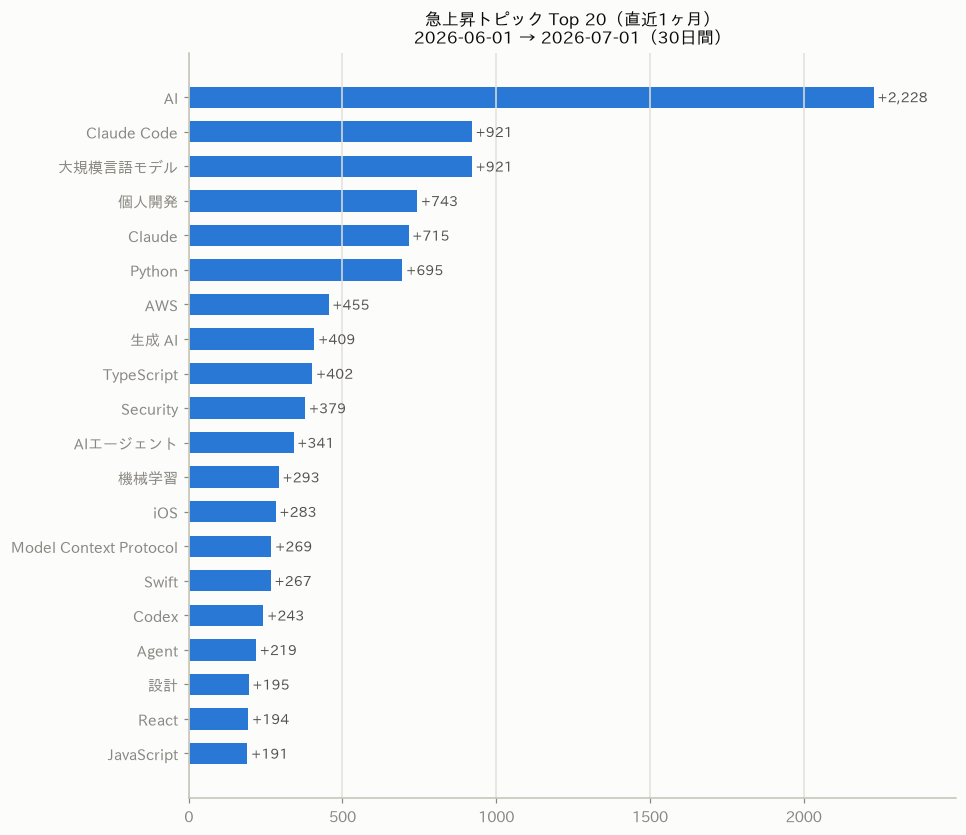

In [5]:
plot_ranking(rank_1m, "急上昇トピック Top 20（直近1ヶ月）")


In [6]:
rank_3m = rising_ranking(months_back=3)
print(rank_3m.attrs["period"])
rank_3m


2026-04-01 → 2026-07-01（91日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
ai,AI,13742,19443,5701,62.65
claudecode,Claude Code,4570,7551,2981,32.76
大規模言語モデル,大規模言語モデル,6278,8456,2178,23.93
claude,Claude,3443,5431,1988,21.85
個人開発,個人開発,3200,4975,1775,19.51
python,Python,14574,16209,1635,17.97
aws,AWS,14718,15958,1240,13.63
security,Security,3652,4772,1120,12.31
typescript,TypeScript,11676,12778,1102,12.11


In [7]:
rank_all = rising_ranking(months_back=None)
print(rank_all.attrs["period"])
rank_all


2025-01-23 → 2026-07-01（524日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
ai,AI,2401,19443,17042,32.52
大規模言語モデル,大規模言語モデル,168,8456,8288,15.82
claudecode,Claude Code,0,7551,7551,14.41
aws,AWS,9511,15958,6447,12.30
python,Python,9817,16209,6392,12.20
claude,Claude,258,5431,5173,9.87
typescript,TypeScript,8144,12778,4634,8.84
個人開発,個人開発,1355,4975,3620,6.91
生成ai,生成 AI,1048,4366,3318,6.33


In [8]:
# 下降トピック（記事の削除・タグ付け替えなどで減少したもの）
rank_down = rising_ranking(months_back=3, ascending=True)
print(rank_down.attrs["period"])
rank_down


2026-04-01 → 2026-07-01（91日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
caio,caio,115,1,-114,-1.25
habits,habits,115,1,-114,-1.25
generativeai,Generative AI,322,233,-89,-0.98
webscraping,webscraping,63,13,-50,-0.55
eccube,EC-CUBE,68,33,-35,-0.38
eccube4,eccube4,33,1,-32,-0.35
proxy,proxy,233,203,-30,-0.33
nkktechglobal,nkktechglobal,18,0,-18,-0.20
クリプトワークス,クリプトワークス,22,6,-16,-0.18


### 相対成長率

絶対数の増加は大型トピックが有利なので、伸び「率」でも見る。
`min_start` で開始時の最低記事数を指定して、母数が小さすぎるトピックのノイズを除く（値を上げると「ある程度定着した中で伸びているもの」になる）。


In [9]:
def growth_ranking(months_back: int | None = 3, min_start: int = 50, top_n: int = 20, ascending: bool = False) -> pd.DataFrame:
    """相対成長率（%）ランキング。開始時に min_start 記事以上あるトピックが対象。"""
    start_date, end_date = snapshot_at(months_back), articles.index[-1]
    start, end = articles.loc[start_date], articles.loc[end_date]
    growth = ((end - start) / start * 100)[(start >= min_start) & end.notna()].dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(growth.index),
        "開始時": start.reindex(growth.index).astype(int),
        "最新": end.reindex(growth.index).astype(int),
        "成長率%": growth.round(1),
    }).sort_values("成長率%", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} → {end_date:%Y-%m-%d}（開始時{min_start}記事以上）"
    return rank


growth_3m = growth_ranking(months_back=3, min_start=50)
print(growth_3m.attrs["period"])
growth_3m


2026-04-01 → 2026-07-01（開始時50記事以上）


,トピック,開始時,最新,成長率%
name,,,,
coreml,Core ML,58,140,141.4
gemma,Gemma,58,128,120.7
エッセイ,エッセイ,56,118,110.7
codex,Codex,604,1269,110.1
agentframework,Microsoft Agent Framework,54,106,96.3
rubykaigi,RubyKaigi,52,102,96.2
music,music,99,189,90.9
ローカルllm,ローカル LLM,301,567,88.4
業務改善,業務改善,78,142,82.1


In [10]:
# 大型トピック（開始時1,000記事以上）に絞ると「定番の中で勢いがあるもの」が見える
growth_large = growth_ranking(months_back=6, min_start=1000)
print(growth_large.attrs["period"])
growth_large


2026-01-01 → 2026-07-01（開始時1000記事以上）


,トピック,開始時,最新,成長率%
name,,,,
claudecode,Claude Code,1900,7551,297.4
claude,Claude,1984,5431,173.7
aiエージェント,AIエージェント,1140,2770,143.0
個人開発,個人開発,2157,4975,130.6
ai,AI,8645,19443,124.9
mcp,Model Context Protocol,1697,2989,76.1
gemini,Gemini,1527,2606,70.7
security,Security,2803,4772,70.2
cli,CLI,1124,1841,63.8


### モメンタム — 勢いが加速・失速しているトピック

直近の区間とその前の区間で「1日あたり増加数」を比較し、伸びが加速しているトピック・失速しているトピックを抽出する。
急上昇ランキングより早くトレンドの変化を捉えられる。


In [11]:
def momentum_ranking(top_n: int = 15, ascending: bool = False) -> pd.DataFrame:
    """直近区間と前区間の増加ペース（/日）を比較した加速ランキング。"""
    d0, d1, d2 = articles.index[-3], articles.index[-2], articles.index[-1]
    rate_prev = (articles.loc[d1] - articles.loc[d0]) / (d1 - d0).days
    rate_now = (articles.loc[d2] - articles.loc[d1]) / (d2 - d1).days
    accel = (rate_now - rate_prev).dropna()
    rank = pd.DataFrame({
        "トピック": display_names.reindex(accel.index),
        "前区間/日": rate_prev.reindex(accel.index).round(2),
        "直近/日": rate_now.reindex(accel.index).round(2),
        "加速": accel.round(2),
    }).sort_values("加速", ascending=ascending).head(top_n)
    rank.attrs["period"] = f"前区間 {d0:%Y-%m-%d}→{d1:%Y-%m-%d} / 直近 {d1:%Y-%m-%d}→{d2:%Y-%m-%d}"
    return rank


mom_up = momentum_ranking()
print(mom_up.attrs["period"])
mom_up


前区間 2026-05-01→2026-06-01 / 直近 2026-06-01→2026-07-01


,トピック,前区間/日,直近/日,加速
name,,,,
ai,AI,58.84,74.27,15.43
大規模言語モデル,大規模言語モデル,20.71,30.70,9.99
python,Python,15.03,23.17,8.13
swift,Swift,1.61,8.90,7.29
個人開発,個人開発,17.87,24.77,6.90
ios,iOS,2.65,9.43,6.79
機械学習,機械学習,5.10,9.77,4.67
generativeai,Generative AI,-4.19,0.40,4.59
workflow,workflow,-2.74,1.73,4.48


In [12]:
# 失速しているトピック（伸びの鈍化。マイナス = 前区間よりペースダウン）
momentum_ranking(ascending=True)


,トピック,前区間/日,直近/日,加速
name,,,,
ai駆動開発,AI駆動開発,2.81,-0.80,-3.61
azure,Azure,5.97,2.77,-3.20
error,error,3.90,0.80,-3.10
chef,chef,1.77,0.00,-1.77
saas,SaaS,3.06,1.33,-1.73
rust,Rust,5.32,3.70,-1.62
ハッカソン,ハッカソン,1.87,0.30,-1.57
openai,OpenAI,4.19,2.97,-1.23
codex,Codex,9.29,8.10,-1.19


### 新規登場トピック

各スナップショットで初めて観測されたトピック。新しい技術・サービスの登場を捉えられる。
コミット間隔が不均一な月（2025-06 は3ヶ月分）は件数が多く見えることに注意。


In [13]:
def newcomer_ranking(months_back: int | None = 3, top_n: int = 20) -> pd.DataFrame:
    """期間中に初登場したトピックを最新記事数の多い順に返す。"""
    start_date = snapshot_at(months_back)
    new = first_seen[first_seen > start_date]
    rank = pd.DataFrame({
        "トピック": display_names.reindex(new.index),
        "初登場": new.dt.strftime("%Y-%m"),
        "最新記事数": articles.iloc[-1].reindex(new.index).fillna(0).astype(int),
    }).sort_values("最新記事数", ascending=False).head(top_n)
    rank.attrs["period"] = f"{start_date:%Y-%m-%d} 以降に初登場"
    return rank


new_6m = newcomer_ranking(months_back=6)
print(new_6m.attrs["period"])
new_6m


2026-01-01 以降に初登場


,トピック,初登場,最新記事数
name,,,
openclaw,OpenClaw,2026-02,341
gch4,gch4,2026-02,175
ハーネスエンジニアリング,ハーネスエンジニアリング,2026-03,134
gemma4,Gemma 4,2026-05,72
amivoice,AmiVoice,2026-06,70
社内研修,社内研修,2026-05,68
agentteams,Agent teams,2026-03,63
bluecode,bluecode,2026-05,62
cowork,Cowork,2026-02,57


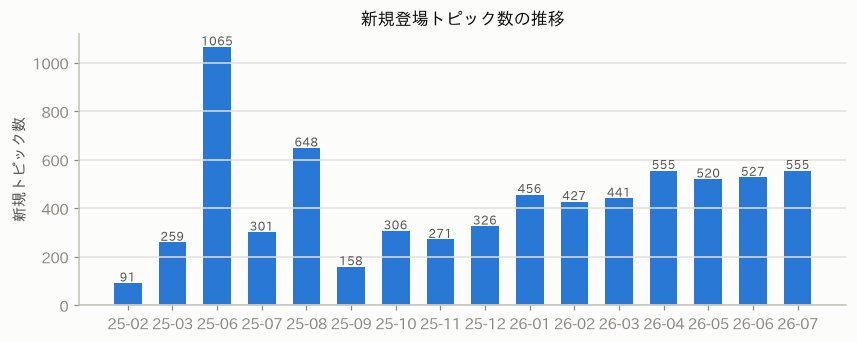

In [14]:
counts = first_seen[first_seen > articles.index[0]].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.bar(counts.index.strftime("%y-%m"), counts.values, color=SERIES[0], width=0.62)
ax.bar_label(bars, color=INK2, fontsize=8)
ax.grid(axis="x", visible=False)
ax.set_ylabel("新規トピック数")
ax.set_title("新規登場トピック数の推移", fontsize=11)
plt.show()


## 3. トピック比較

比較の基本形は `compare_topics([...])`。**左に絶対数（記事数の推移）、右に相対成長（出揃った時点 = 100 の指数）**をセットで表示する。
左で規模感を、右で成長スピードを見る（規模が違うトピック同士でも右のパネルで公平に比較できる）。

`plot_topics([...])` は単発の折れ線で、オプションで切り口を変えられる:

- `rate=True` : スナップショット間の「1日あたり増加数」（勢いの変化）
- `normalize=True` : 指数表示のみ
- `metric=` : taggings / scraps / books / share などのマトリクスに切り替え
- 新規登場トピックは登場時点より前を欠損として扱う（0埋めしない）
- トピック名がわからないときは `search_topics("キーワード")` で探せる


In [15]:
def plot_topics(topics: list[str], rate: bool = False, normalize: bool = False,
                metric: pd.DataFrame | None = None, title: str | None = None,
                ylabel: str | None = None, ax=None, legend: bool = True,
                min_base: int = 20) -> None:
    """指定トピックの推移を折れ線で比較する（最大8トピック）。

    rate=True      : スナップショット間の1日あたり増加数（勢いの比較）
    normalize=True : 指数表示（規模が違うトピックの比較）。母数が小さい時点を基準にすると
                     指数が暴れるため、全トピックが min_base 以上になった最初の時点を 100 とする。
                     それでも最終値の開きが30倍を超える場合は対数軸に自動で切り替える
    metric         : articles 以外のマトリクス（taggings / scraps / share など）
    ax             : small multiples 用の描画先 Axes
    """
    m = articles if metric is None else metric
    if missing := [t for t in topics if t not in m.columns]:
        raise KeyError(f"存在しないトピック: {missing}（search_topics() で探せます）")
    if len(topics) > len(SERIES):
        raise ValueError(f"一度に比較できるのは{len(SERIES)}トピックまでです")

    sub = m[list(topics)]
    if rate:
        sub = sub.diff().div(sub.index.to_series().diff().dt.days, axis=0)
        default_ylabel, default_title = "増加数/日", "トピック別 記事数の増加ペース"
    elif normalize:
        ok = (sub >= min_base).all(axis=1)
        base = ok.idxmax() if ok.any() else max(sub[t].first_valid_index() for t in topics)
        sub = (sub / sub.loc[base] * 100).loc[base:]
        finals = sub.iloc[-1].dropna()
        log_scale = finals.max() > 30 * max(finals.min(), 1)
        default_ylabel = f"指数（{base:%Y-%m-%d} = 100" + ("、対数）" if log_scale else "）")
        default_title = "トピック別 相対成長"
    else:
        default_ylabel, default_title = "記事数", "トピック別 記事数の推移"

    own_fig = ax is None
    if own_fig:
        _, ax = plt.subplots()
    span = (sub.max().max() - min(0, sub.min().min())) or 1
    labeled: list[float] = []
    for color, topic in zip(SERIES, topics):
        s = sub[topic].dropna()
        if s.empty:
            continue
        ax.plot(s.index, s.values, color=color, label=display_names.get(topic, topic),
                marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
        v = s.iloc[-1]
        # 系列が少なく、既存ラベルと重ならないときだけ終端に値を直接ラベル
        if own_fig and len(topics) <= 4 and all(abs(v - u) > 0.05 * span for u in labeled):
            ax.annotate(f" {v:,.0f}" if v >= 100 else f" {v:,.1f}", (s.index[-1], v),
                        color=INK2, fontsize=9, va="center")
            labeled.append(v)
    locator = mdates.AutoDateLocator(maxticks=10 if own_fig else 6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    if legend:
        ax.legend(frameon=False, labelcolor=INK2, fontsize=9)
    ax.set_ylabel(ylabel or default_ylabel)
    if normalize and log_scale:
        ax.set_yscale("log")
    else:
        ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
    ax.set_title(title or default_title, fontsize=11)
    ax.margins(x=0.06)
    if own_fig:
        plt.show()


def compare_topics(topics: list[str], title: str | None = None,
                   metric: pd.DataFrame | None = None) -> None:
    """絶対数（左）と相対成長の指数（右）をセットで表示する。比較の基本形。"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
    plot_topics(topics, metric=metric, ax=ax1, title="記事数の推移")
    plot_topics(topics, metric=metric, normalize=True, ax=ax2,
                title="相対成長", legend=False)  # 色は左と共通なので凡例は左のみ
    if title:
        fig.suptitle(title, fontsize=13)
    plt.show()


### AI関連トピック


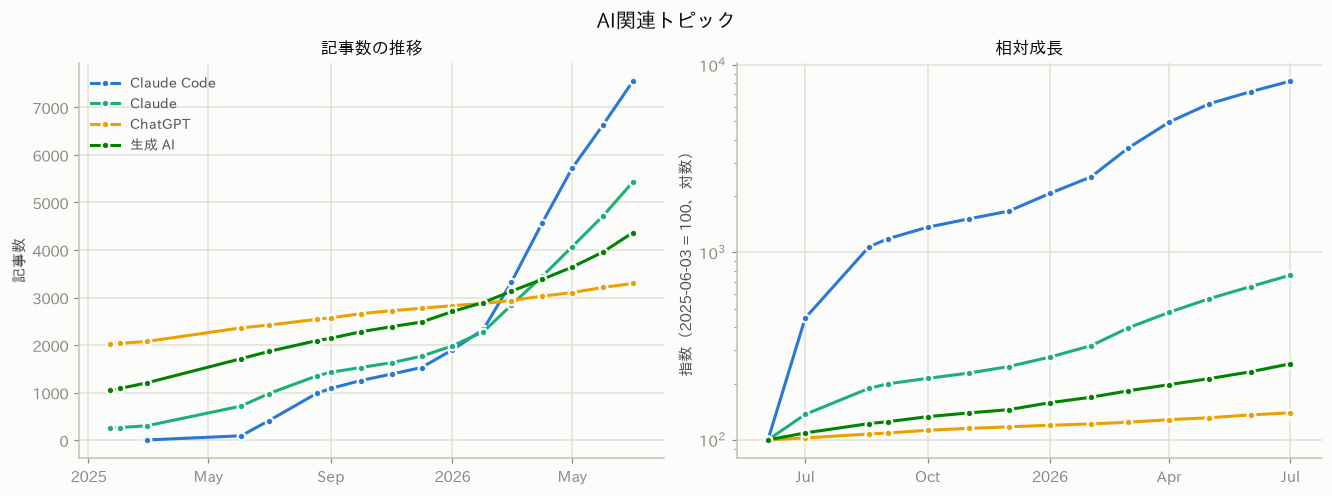

In [16]:
compare_topics(["claudecode", "claude", "chatgpt", "生成ai"], title="AI関連トピック")


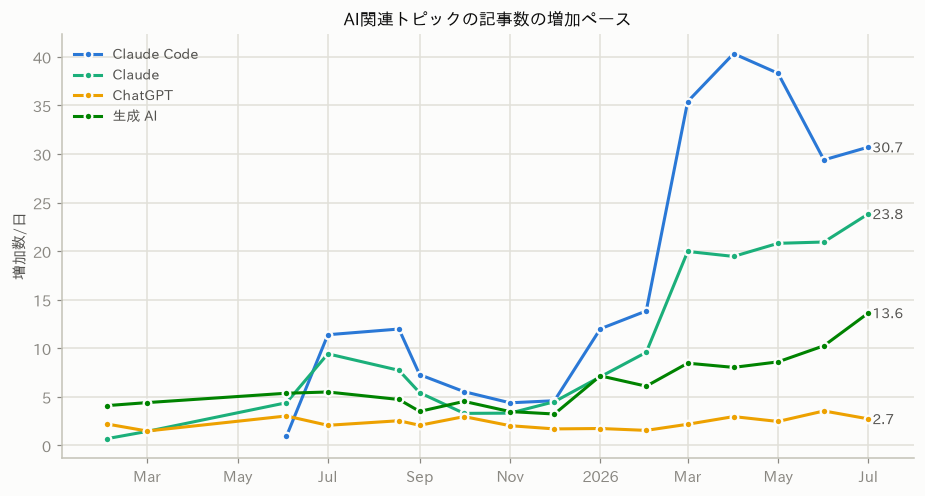

In [17]:
# 勢い（1日あたり増加数）の変化
plot_topics(["claudecode", "claude", "chatgpt", "生成ai"], rate=True,
            title="AI関連トピックの記事数の増加ペース")


### フロントエンド


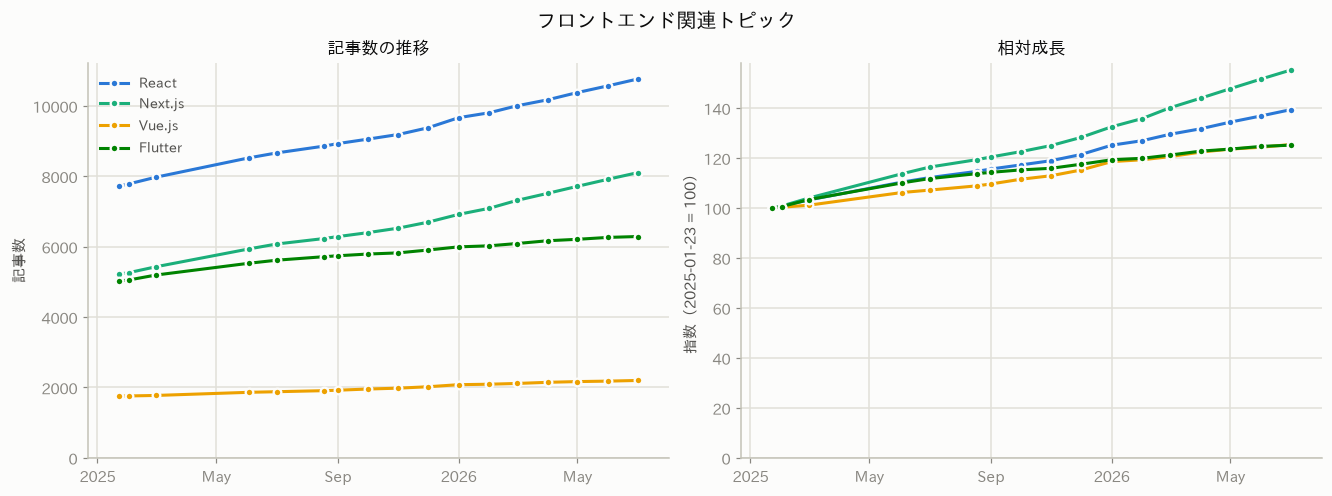

In [18]:
compare_topics(["react", "nextjs", "vue", "flutter"], title="フロントエンド関連トピック")


### Nix と環境構築ツール

Nix を同じ「開発環境・パッケージ/環境管理」領域のツールと比較する。
テーブルには規模の違う Docker / WSL2 も含めてある（グラフは同規模帯のツールで比較）。


In [19]:
ENV_TOOLS = ["nix", "nixos", "devcontainer", "homebrew", "mise", "asdf",
             "dotfiles", "direnv", "chezmoi", "podman", "docker", "wsl2"]
start, end = articles.iloc[0], articles.iloc[-1]
pd.DataFrame({
    "トピック": display_names.reindex(ENV_TOOLS),
    "開始時": start.reindex(ENV_TOOLS).fillna(0).astype(int),
    "最新": end.reindex(ENV_TOOLS).astype(int),
    "増加数": (end - start.fillna(0)).reindex(ENV_TOOLS).astype(int),
    "成長率%": ((end - start) / start * 100).reindex(ENV_TOOLS).round(1),
}).sort_values("成長率%", ascending=False)


,トピック,開始時,最新,増加数,成長率%
name,,,,,
nixos,NixOS,16,71,55,343.8
mise,mise,35,145,110,314.3
chezmoi,chezmoi,12,41,29,241.7
dotfiles,dotfiles,66,187,121,183.3
nix,Nix,80,218,138,172.5
direnv,direnv,17,40,23,135.3
devcontainer,dev container,232,477,245,105.6
podman,podman,81,153,72,88.9
wsl2,WSL 2,558,899,341,61.1


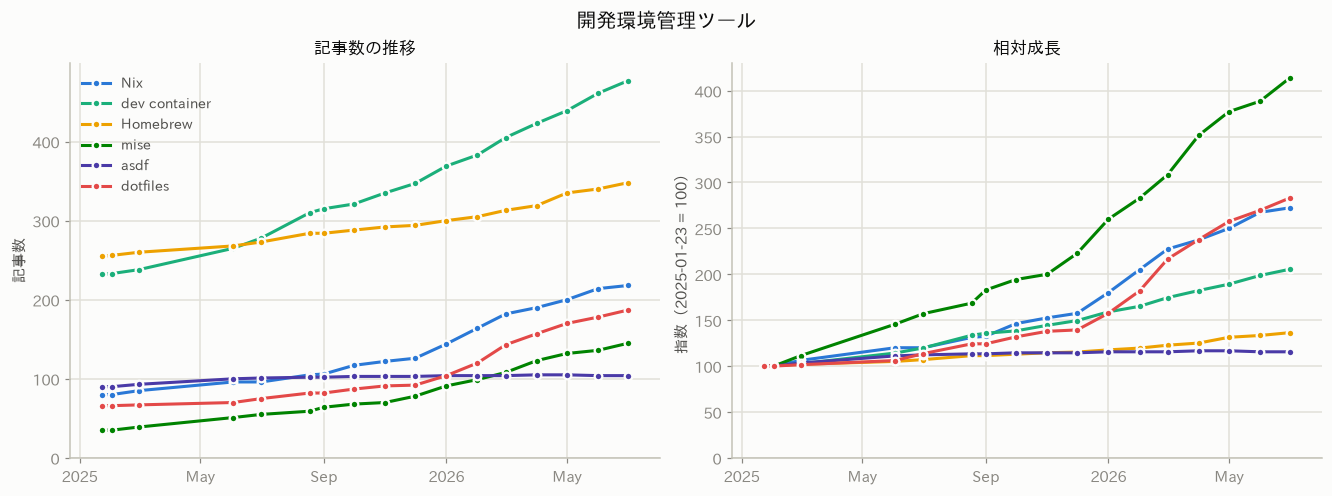

In [20]:
compare_topics(["nix", "devcontainer", "homebrew", "mise", "asdf", "dotfiles"],
               title="開発環境管理ツール")


### ネイティブアプリ開発

OS ネイティブ系（iOS / Android）とクロスプラットフォーム系（Flutter / React Native / Electron / Tauri など）。
クロスプラットフォーム系は規模差が大きい（Flutter 6,000超 〜 Tauri 300弱）ので、右の相対成長パネルが効く。


In [21]:
NATIVE_TOPICS = ["flutter", "reactnative", "expo", "swift", "swiftui", "ios", "android",
                 "kotlin", "jetpackcompose", "kmp", "electron", "tauri", "maui",
                 "capacitor", "ionic", "pwa", "xcode", "uikit", "dart"]
start, end = articles.iloc[0], articles.iloc[-1]
pd.DataFrame({
    "トピック": display_names.reindex(NATIVE_TOPICS),
    "開始時": start.reindex(NATIVE_TOPICS).fillna(0).astype(int),
    "最新": end.reindex(NATIVE_TOPICS).astype(int),
    "増加数": (end - start.fillna(0)).reindex(NATIVE_TOPICS).astype(int),
    "成長率%": ((end - start) / start * 100).reindex(NATIVE_TOPICS).round(1),
}).sort_values("成長率%", ascending=False)


,トピック,開始時,最新,増加数,成長率%
name,,,,,
tauri,Tauri,109,295,186,170.6
pwa,PWA,83,181,98,118.1
electron,Electron,130,258,128,98.5
expo,Expo,276,500,224,81.2
android,Android,2300,3499,1199,52.1
reactnative,React Native,647,971,324,50.1
maui,MAUI,44,66,22,50.0
ios,iOS,3003,4451,1448,48.2
swift,Swift,2562,3548,986,38.5


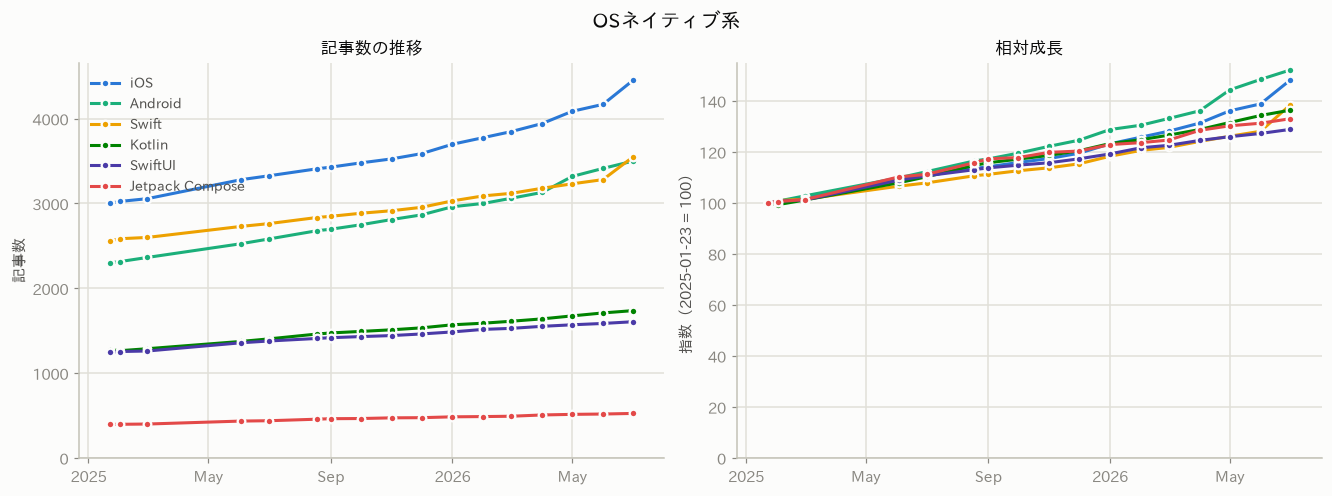

In [22]:
compare_topics(["ios", "android", "swift", "kotlin", "swiftui", "jetpackcompose"],
               title="OSネイティブ系")


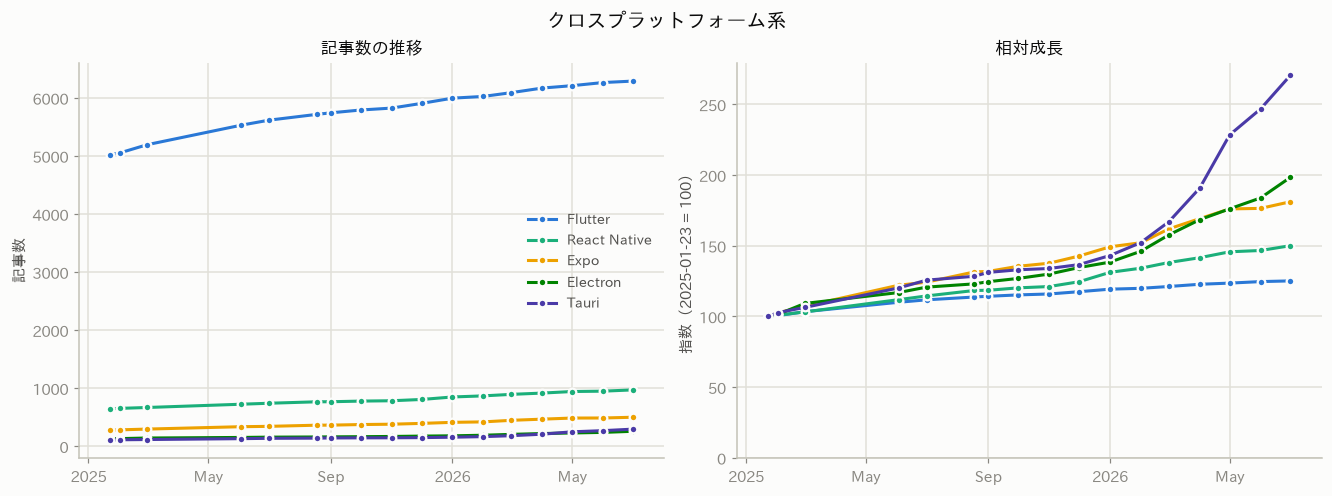

In [23]:
compare_topics(["flutter", "reactnative", "expo", "electron", "tauri"],
               title="クロスプラットフォーム系")


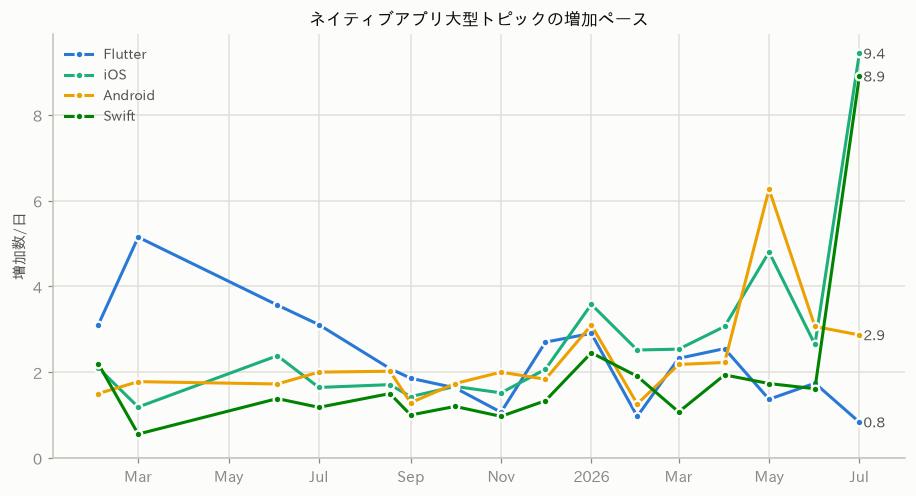

In [24]:
# 大型トピックの増加ペース（AIブームの中でネイティブアプリの執筆ペースはどう変わったか）
plot_topics(["flutter", "ios", "android", "swift"], rate=True,
            title="ネイティブアプリ大型トピックの増加ペース")


### テーマ別一覧（small multiples）

`THEMES` を書き換えれば任意のテーマセットで一覧比較できる。


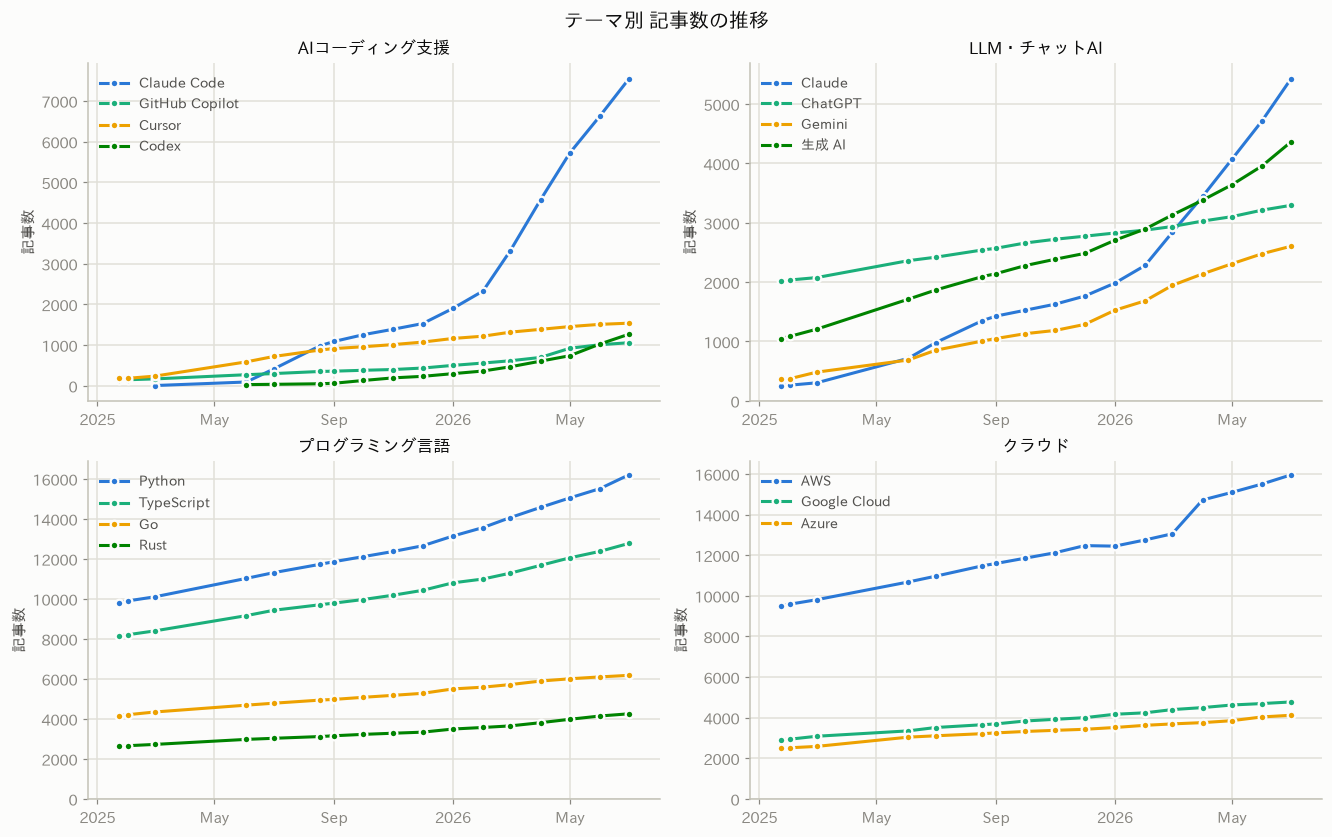

In [25]:
THEMES = {
    "AIコーディング支援": ["claudecode", "githubcopilot", "cursor", "codex"],
    "LLM・チャットAI": ["claude", "chatgpt", "gemini", "生成ai"],
    "プログラミング言語": ["python", "typescript", "go", "rust"],
    "クラウド": ["aws", "googlecloud", "azure"],
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
for ax, (theme, topics) in zip(axes.flat, THEMES.items()):
    plot_topics(topics, ax=ax, title=theme)
fig.suptitle("テーマ別 記事数の推移", fontsize=13)
plt.show()


## 4. マクロ視点

### 全体に占めるシェアの推移

記事の絶対数はどのトピックも増え続けるので、「Zenn 全体のタグ付けに占める割合」で相対的な人気の変化を見る。
シェアが下がっていても絶対数は増えていることが多い点に注意。


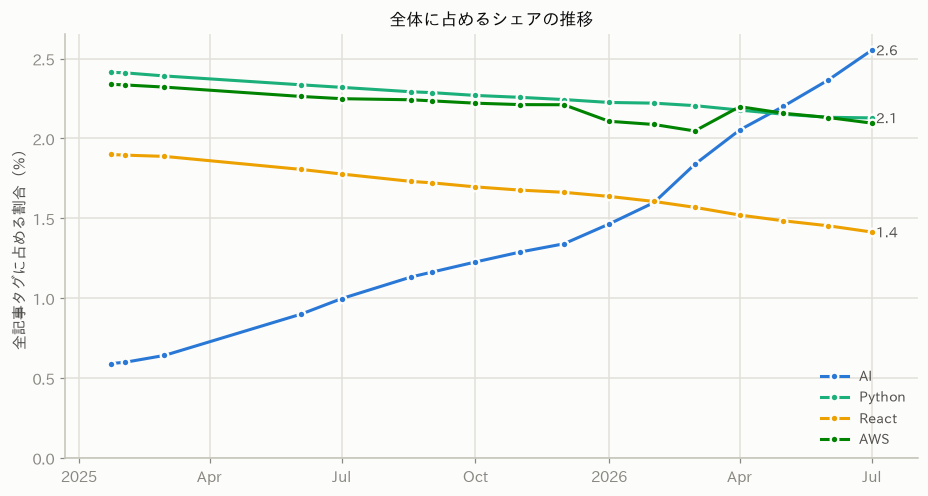

In [26]:
share = articles.div(articles.sum(axis=1), axis=0) * 100
plot_topics(["ai", "python", "react", "aws"], metric=share,
            ylabel="全記事タグに占める割合（%）", title="全体に占めるシェアの推移")


### AI関連 vs それ以外

トピック名・表示名のキーワードマッチで「AI関連トピック」を判定し、タグ付け数を AI / 非AI に分けて比較する。

- 判定は `looks_ai()` のヒューリスティック。次のセルでマッチしたトピック一覧を確認できるので、誤検出があれば正規表現を調整する
- 記事は複数タグを持てるため、ここで数えているのは記事数そのものではなく「記事×トピックのタグ付け数」。AI と非AI の両方のタグを持つ記事は両側に計上される
- Zenn 側でトピックが改名されることがある（例: 2026年2〜3月に `llm` → `大規模言語モデル` に統合）。改名の前後で両方が AI 判定になっていれば合計はほぼ滑らかにつながる


In [27]:
import re

# 単語としての "ai"（英数字が隣接しない位置。airflow や mail は除外される）
WORD_AI = re.compile(r"(?:^|[^a-z0-9])ai(?:[^a-z0-9]|$)")
# AI・機械学習・LLM周辺のキーワード（部分一致で安全なものだけ。grok は ngrok を避けて先頭一致）
AI_KEYWORDS = re.compile(
    "llm|言語モデル|gpt|claude|gemini|copilot|openai|anthropic|genai|generativeai|人工知能|"
    "langchain|llamaindex|huggingface|deeplearning|machinelearning|mlops|mlflow|"
    "scikitlearn|pytorch|tensorflow|keras|kaggle|"
    "stablediffusion|diffusion|midjourney|comfyui|imagen|"
    "prompt|プロンプト|機械学習|深層学習|ディープラーニング|ニューラルネット|強化学習|"
    "生成ai|画像生成|動画生成|音声生成|チャットボット|chatbot|aituber|"
    "vibecoding|バイブコーディング|"
    "bedrock|vertexai|sagemaker|cursor|codex|devin|cline|roocode|windsurf|kiro|aider|"
    "whisper|transformer|ollama|llama|mistral|deepseek|(?:^|[^a-z])grok|perplexity|notebooklm|"
    "nlp|自然言語処理|音声認識|物体検出|embedding|ベクトル検索|ベクトルデータベース|finetun|ファインチューニング|"
    "^rag$|agent|エージェント|mcp|dify|vllm|gguf|gemma|qwen"
)


def looks_ai(slug: str) -> bool:
    disp = str(display_names.get(slug, "")).lower()
    return bool(WORD_AI.search(slug) or WORD_AI.search(disp)
                or AI_KEYWORDS.search(slug) or AI_KEYWORDS.search(disp))


ai_topics = [t for t in articles.columns if looks_ai(t)]
print(f"AI関連と判定: {len(ai_topics):,} / {articles.shape[1]:,} トピック")

# 判定結果の確認（最新記事数の上位。誤検出がないか眺める）
pd.DataFrame({
    "トピック": display_names.reindex(ai_topics),
    "最新記事数": articles.iloc[-1].reindex(ai_topics).fillna(0).astype(int),
}).sort_values("最新記事数", ascending=False).head(30)


AI関連と判定: 610 / 17,674 トピック


,トピック,最新記事数
name,,
ai,AI,19443
大規模言語モデル,大規模言語モデル,8456
claudecode,Claude Code,7551
claude,Claude,5431
生成ai,生成 AI,4366
機械学習,機械学習,3700
chatgpt,ChatGPT,3295
mcp,Model Context Protocol,2989
aiエージェント,AIエージェント,2770


最新のタグ付け数: AI 97,432 / 非AI 663,986（累計シェア 12.8% ← 期初 5.0%）
全期間の増加分: AI 77,090 / 非AI 277,729


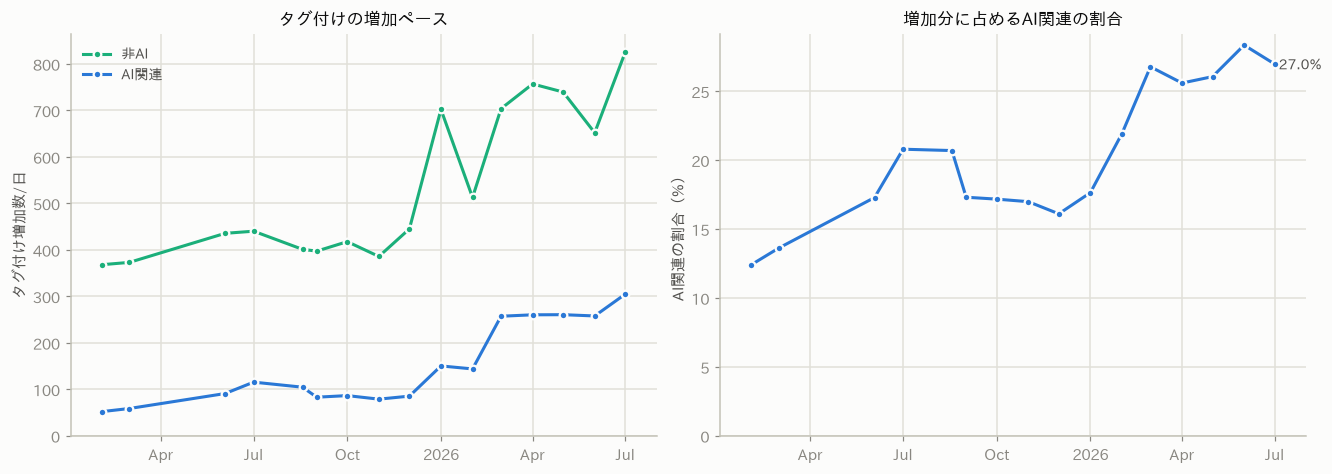

In [28]:
ai_total = articles[ai_topics].sum(axis=1)
nonai_total = articles.sum(axis=1) - ai_total

days = articles.index.to_series().diff().dt.days
ai_rate, nonai_rate = ai_total.diff() / days, nonai_total.diff() / days
growth_share = (ai_total.diff() / (ai_total.diff() + nonai_total.diff()) * 100).dropna()
cum_share = ai_total / (ai_total + nonai_total) * 100

print(f"最新のタグ付け数: AI {ai_total.iloc[-1]:,.0f} / 非AI {nonai_total.iloc[-1]:,.0f}"
      f"（累計シェア {cum_share.iloc[-1]:.1f}% ← 期初 {cum_share.iloc[0]:.1f}%）")
print(f"全期間の増加分: AI {ai_total.iloc[-1] - ai_total.iloc[0]:,.0f} /"
      f" 非AI {nonai_total.iloc[-1] - nonai_total.iloc[0]:,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")

for s, label, color in [(nonai_rate.dropna(), "非AI", SERIES[1]), (ai_rate.dropna(), "AI関連", SERIES[0])]:
    ax1.plot(s.index, s.values, color=color, label=label,
             marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax1.legend(frameon=False, labelcolor=INK2, fontsize=9)
ax1.set_ylabel("タグ付け増加数/日")
ax1.set_ylim(bottom=0)
ax1.set_title("タグ付けの増加ペース", fontsize=11)

ax2.plot(growth_share.index, growth_share.values, color=SERIES[0],
         marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax2.annotate(f" {growth_share.iloc[-1]:.1f}%", (growth_share.index[-1], growth_share.iloc[-1]),
             color=INK2, fontsize=9, va="center")
ax2.set_ylabel("AI関連の割合（%）")
ax2.set_ylim(bottom=0)
ax2.set_title("増加分に占めるAI関連の割合", fontsize=11)

for ax in (ax1, ax2):
    locator = mdates.AutoDateLocator(maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.margins(x=0.06)
plt.show()


### 成長ヒートマップ — いつ盛り上がったか

トピック × 期間で増加ペース（/日）をヒートマップ表示する。各行はそのトピックのピーク = 1 に正規化してあるので、
色の濃い場所が「そのトピックが最も盛り上がった時期」。空白は未登場の期間。


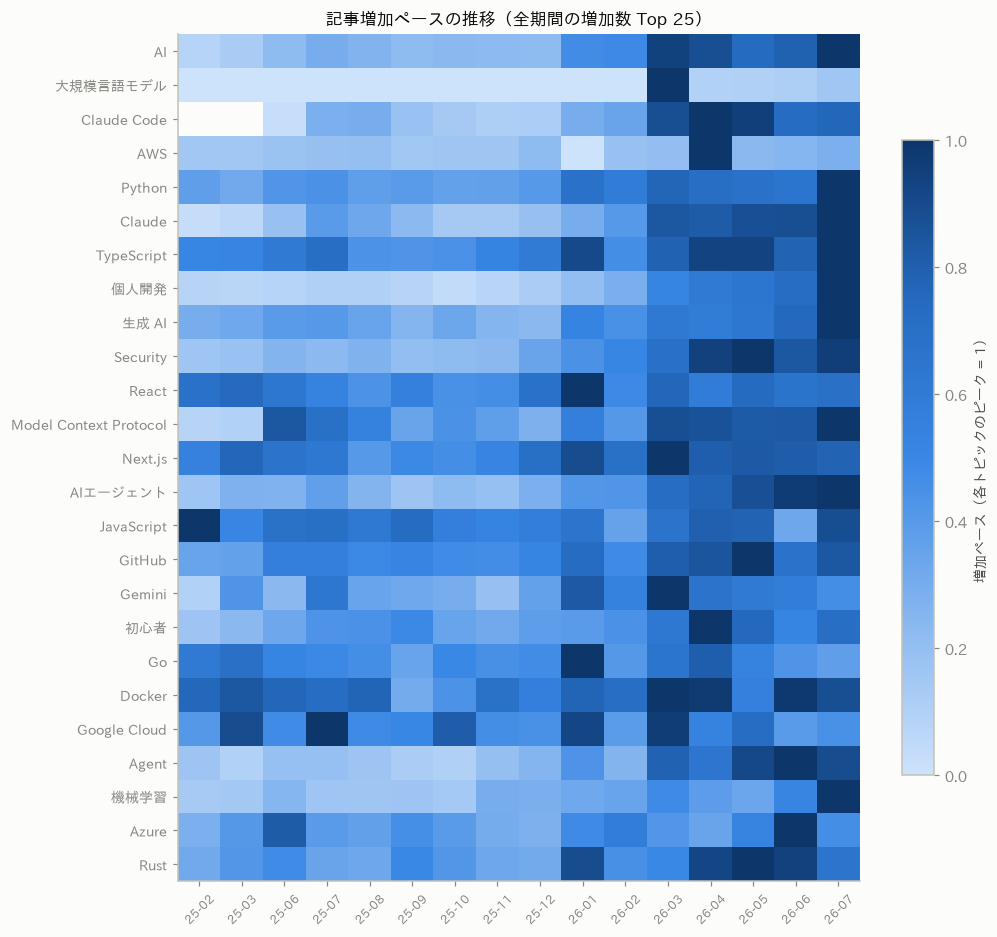

In [29]:
from matplotlib.colors import LinearSegmentedColormap

BLUES = LinearSegmentedColormap.from_list(
    "seq-blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
BLUES.set_bad(SURFACE)


def plot_growth_heatmap(topics: list[str] | None = None, top_n: int = 25) -> None:
    """トピック × 期間の増加ペースをヒートマップ表示（各行はピーク=1に正規化）。"""
    rate = articles.diff().div(articles.index.to_series().diff().dt.days, axis=0).iloc[1:]
    if topics is None:  # 指定がなければ全期間の増加数 Top N
        total = (articles.iloc[-1] - articles.iloc[0].fillna(0)).dropna()
        topics = total.sort_values(ascending=False).head(top_n).index.tolist()
    peak = rate[topics].max()
    data = rate[topics].div(peak.where(peak > 0)).T

    fig, ax = plt.subplots(figsize=(10, 0.34 * len(topics) + 1.5))
    mesh = ax.imshow(data.values, cmap=BLUES, aspect="auto", vmin=0, vmax=1)
    ax.set_yticks(range(len(topics)), [display_names.get(t, t) for t in topics], fontsize=9)
    ax.set_xticks(range(len(rate)), [f"{d:%y-%m}" for d in rate.index],
                  fontsize=8, rotation=45)
    ax.grid(False)
    cbar = fig.colorbar(mesh, ax=ax, shrink=0.75)
    cbar.set_label("増加ペース（各トピックのピーク = 1）", fontsize=9, color=INK2)
    ax.set_title("記事増加ペースの推移（全期間の増加数 Top 25）", fontsize=11)
    plt.show()


plot_growth_heatmap()


## 5. 記事以外の指標 — スクラップ・本

`metric=` を差し替えるだけで記事以外のカウントも同じ関数で分析できる。
スクラップは作業ログ・議論なので「いま試されている技術」が記事より早く現れやすい。


In [30]:
rank_scraps = rising_ranking(months_back=3, metric=scraps, top_n=15)
print("スクラップの増加:", rank_scraps.attrs["period"])
rank_scraps


スクラップの増加: 2026-04-01 → 2026-07-01（91日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
cpp,C++,194,264,70,0.77
claudecode,Claude Code,184,240,56,0.62
rag,RAG,244,285,41,0.45
ai,AI,352,391,39,0.43
rust,Rust,859,896,37,0.41
大規模言語モデル,大規模言語モデル,808,845,37,0.41
windows,Windows,209,243,34,0.37
python,Python,1040,1073,33,0.36
gemma4,Gemma 4,0,33,33,0.36


In [31]:
rank_books = rising_ranking(months_back=None, metric=books, top_n=15)
print("本の増加:", rank_books.attrs["period"])
rank_books


本の増加: 2025-01-23 → 2026-07-01（524日間）


,トピック,開始時,最新,増加数,増加数/日
name,,,,,
ai,AI,59,385,326,0.62
python,Python,207,392,185,0.35
claudecode,Claude Code,0,126,126,0.24
大規模言語モデル,大規模言語モデル,0,123,123,0.23
typescript,TypeScript,157,264,107,0.20
react,React,153,233,80,0.15
claude,Claude,0,78,78,0.15
生成ai,生成 AI,12,87,75,0.14
nextjs,Next.js,125,197,72,0.14


## 6. 付録 — トピック検索

比較したいトピックのスラッグを探すときに使う。


In [32]:
search_topics("gemini").head(10)


,トピック,最新記事数
name,,
gemini,Gemini,2606
geminicli,Gemini CLI,302
geminiapi,Gemini API,111
gemini3,Gemini 3,15
gemininano,Gemini Nano,11
geminipro,Gemini Pro,6
geminienterprise,geminienterprise,5
geminicodeassist,Gemini Code Assist,5
gemini20,Gemini 2.0,3
